# mouse

load the data and a trained model, couple one clone, and look at the output tables. `../runs/cand1` is the main model; `data.root + '/model'` holds the paper's weights.

In [1]:
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from hydra.utils import instantiate
from omegaconf import OmegaConf

from li.eval import fills
from li.eval.couple import couple
from li.eval.metrics import germ_crossing
from li.eval.nodes import clade, crossing, label, summarize, to_anndata
from li.model.net import load_sampler
from li.plot import tree as pt, umap as pu

data = instantiate(OmegaConf.load("../config/data/mouse.yaml"), device="cuda", _convert_="all")
run = "../runs/cand1"
net = load_sampler(run)

## couple one clone

for every internal node from E7.0 on: a real cell per sample, and the snap distance (the raw sampled state to that cell).

In [2]:
name = "E9.5-R2-C3"
one = SimpleNamespace(trees={name: data.trees[name]}, bank=data.bank)
coup = label(couple(fills.sampler(net), one, n_samples=4), data.labels)
coup.head()

,tree,node,time,cell,dist,sample,subtype,cell_type,lineage,germ_layer
0,E9.5-R2-C3,5TsMhRtw,7.368815,E8.0-R3-T1-CACCGAACAAACTACA-1,4.622678,0,midbrain,midbrain,neural ectoderm,ectoderm
1,E9.5-R2-C3,JVzVPHf8,8.379580,E9.0-R3-T6-CACAATTAGTACGCTA-1,4.230611,0,midbrain,midbrain,neural ectoderm,ectoderm
2,E9.5-R2-C3,JO25nzTk,8.669638,E9.0-R2-T3-AGCTAACCAGCCAAGC-1,5.402450,0,midbrain,midbrain,neural ectoderm,ectoderm
3,E9.5-R2-C3,IAoL7osd,8.911647,E8.5-R3-T1-CGGGTAGGTTCCCTTA-1,3.310875,0,midbrain,midbrain,neural ectoderm,ectoderm
4,E9.5-R2-C3,0BnZEYBY,8.964159,E9.0-R2-T2-TACGCATGTGAGCACG-1,3.855409,0,midbrain,midbrain,neural ectoderm,ectoderm


## per node

the modal type over samples, the share of samples that agree with it, label entropy, and the mean snap distance.

In [3]:
nodes = summarize(coup)
nodes.groupby(nodes.time.round(1)).agg(n=("node", "size"), agreement=("agreement", "mean"),
                                       entropy=("entropy", "mean"), dist=("dist", "mean")).round(2)

,n,agreement,entropy,dist
time,,,,
7.0,5,0.65,0.67,4.25
7.1,3,0.58,0.77,4.93
7.2,7,0.61,0.82,6.02
7.3,11,0.66,0.70,5.06
7.4,5,0.80,0.28,5.36
7.5,10,0.75,0.42,5.06
7.6,19,0.63,0.70,5.41
7.7,19,0.62,0.77,5.50
7.8,20,0.54,0.89,5.46


In [4]:
germ_crossing(coup, one.trees, data.labels["germ_layer"], data.bank.times)

,sample,bin,n_edges,rate
0,0,all,1429,0.068579
1,0,7.5,167,0.095808
2,0,8.0,509,0.100196
3,0,8.5,611,0.045827
4,0,9.0,142,0.021127
5,1,all,1427,0.062369
6,1,7.5,174,0.120690
7,1,8.0,494,0.082996
8,1,8.5,619,0.038772
9,1,9.0,140,0.021429


## the whole run

`evaluate.py` writes the same table for every clone, `coupling_<fill>.parquet`, plus `nodes_<fill>.parquet` (per node) and `germ_<fill>.csv`. as anndata, for scanpy:

In [5]:
full = pd.read_parquet(f"{run}/coupling_sampler.parquet", filters=[("tree", "==", name)])
to_anndata(full, data)

AnnData object with n_obs × n_vars = 6272 × 0
    obs: 'tree', 'node', 'time', 'cell', 'dist', 'sample', 'subtype', 'cell_type', 'lineage', 'germ_layer'
    obsm: 'X_scvi', 'X_umap'

## a clade

left: the card, with time along x and one row per leaf. edges take the child's modal type, faded where samples disagree; ticks are the samples; red x marks an edge that crosses germ layers. right: the atlas umap (grey) with the clade's leaves and each sample's ancestors joined parent to child, coloured by time.

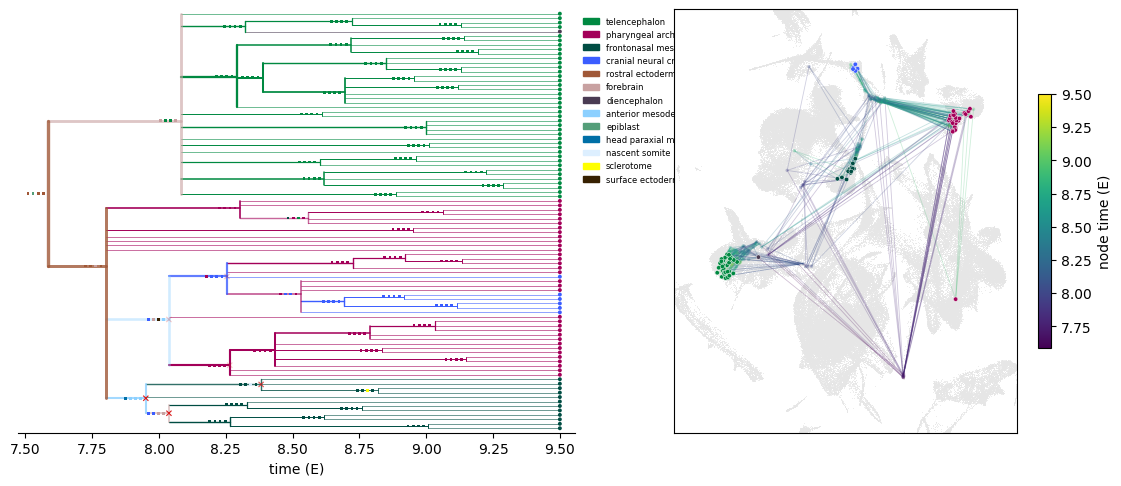

In [6]:
t = data.trees[name]
nl = t.n_leaves()
r = np.flatnonzero(~t.leaf & (nl >= 40) & (nl <= 120) & (t.time >= 7.5))[0]
lab = clade(data, coup, t, r)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw=dict(width_ratios=[1.3, 1]))
pt.card(ax[0], t, r, lab, data.colors, crossing(data, coup, t, r))
pt.key(ax[0], lab, data.colors, loc="upper left", bbox_to_anchor=(1, 1), fontsize=6)
pu.atlas(ax[1], data.umap)
norm = pu.path(ax[1], data.umap, t, r, clade(data, coup, t, r, "cell"), data.colors, lab[t.leaf[r:t.end[r]], 0])
fig.colorbar(plt.cm.ScalarMappable(norm, "viridis"), ax=ax[1], label="node time (E)", shrink=0.6);